# Aphasia examples — binary classifier & severity regression (voxel space, covariate-aware)

Two worked examples matching a common clinical setup, at **4 mm** and controlling for **age + sex**:

1. **Binary classifier** — *aphasia: yes / no* (a binary deficit).
2. **Severity regression** — a *continuous* aphasia-severity score.

For each we recover the neural **substrate** with all four methods — **VLSM**, **SVR-LSM**, the
**MLP-VAE**, and the **conv-VAE** (3D-convolutional) — each run **covariate-blind vs covariate-aware**
(age + sex as nuisance covariates, standard *partialing-out* control). The conv-VAE is the strongest
recoverer and the one covariate-awareness reliably helps.

**Resolution — why 4 mm here.** With cohorts in the hundreds and no per-voxel ground truth, the
binding constraint is statistical power *per voxel*. 4 mm gives a few thousand well-covered voxels
(good power, little overfitting, tractable). 2 mm (~200k voxels) with N in the hundreds is
underpowered per test and overfit-prone — worthwhile only as a *refinement* once 4 mm works, and
then with aggressive coverage-restriction and the conv-VAE (whose spatial prior is what makes higher
resolution viable). **Start at 4 mm; escalate to 2 mm later.**

The conv-VAE is GPU-trained, so its maps here are **precomputed** on a shipped 4 mm sample; the fast
methods (VLSM / SVR-LSM / MLP-VAE) run live at the end so you can see the exact API to plug your data
into. Aphasia → the NeuroQuery **`language`** substrate is the ground truth in these demos.

In [1]:
import sys; sys.path.insert(0, "src")
import json
import numpy as np
import matplotlib.pyplot as plt

from voxel_data import VoxelData
from deficits import make_covariate_benchmark_deficits
from baselines.vlsm import vlsm_binary, vlsm_stat
from baselines.svr_lsm import svr_binary, svr_weights
from metrics import dice, dice_at_k, focal_mass_mask, age_exposure, leakage
from dlm.mlp_vae import fit_parcel_vae
from dlm import conv_vae   # GPU; used for the precomputed maps + the reproduce snippet

METHODS = ["vlsm", "svr", "mlp_vae", "conv_vae"]
SUB = "language"   # aphasia substrate
data = VoxelData.load("voxel_data_sample/voxel_ds.npz")
m = data.substrates[SUB]; k = int(m.sum())
# rebuild the (deterministic) age/sex covariates the precomputed runs used
_, cov = make_covariate_benchmark_deficits(data.X, m.astype(np.float32), data.centroids,
                                            K_parcel=data.n_voxels, beta_main=0.5, beta_int=0.5,
                                            rho=0.5, seed=0)
exposure = age_exposure(data.X, cov)
print(f"V_cov={data.n_voxels}  N={data.n_patients}  substrate={SUB} |M|={k}  "
      f"covariates: age (corr with lesion volume {np.corrcoef(cov[:,0], data.X.sum(1))[0,1]:+.2f}) + sex")

V_cov=2541  N=512  substrate=language |M|=127  covariates: age (corr with lesion volume +0.50) + sex


## How the precomputed maps are scored

Each GPU run saved, per method and per mode (blind/aware), a continuous **score map** and the
method's self-thresholded **mask**. We score them exactly as for the live methods: **Dice@k**
(top-|M| ranking), **binary Dice** (the mask vs truth), and **leakage** (how much off-target weight
tracks the age confound — lower is better).

In [2]:
def score_maps(npz_path, task_key):
    """Load a saved-maps npz and score every method x {blind,aware} for `SUB`."""
    z = dict(np.load(npz_path, allow_pickle=False))
    out = {meth: {} for meth in METHODS}
    for meth in METHODS:
        for mode in ("blind", "aware"):
            s = z[f"{SUB}|{task_key}|{meth}|{mode}|score"].astype(np.float64)
            mask = z[f"{SUB}|{task_key}|{meth}|{mode}|mask"].astype(bool)
            out[meth][mode] = {"dice_k": dice_at_k(s, m, k), "dice_bin": dice(mask, m),
                               "leak": leakage(s, m, exposure), "score": s, "mask": mask}
    return out

def show_table(res, title):
    print(f"{title}\n{'method':10s}" +
          "".join(f"{x:>9s}" for x in ("Dk_bl","Dk_aw","bin_bl","bin_aw","leak_bl","leak_aw")))
    for meth in METHODS:
        b, a = res[meth]["blind"], res[meth]["aware"]
        print(f"{meth:10s}{b['dice_k']:>9.3f}{a['dice_k']:>9.3f}{b['dice_bin']:>9.3f}"
              f"{a['dice_bin']:>9.3f}{b['leak']:>9.3f}{a['leak']:>9.3f}")

## Example 1 — binary aphasia classifier (aphasia yes/no)

A binary deficit (substrate-coverage rule) with age/sex covariates. This is the classifier setting:
`y ∈ {0,1}`. Precomputed results (all four methods, blind → aware):

In [3]:
binary = score_maps("james_maps_binary.npz", "coverage")
show_table(binary, "BINARY aphasia classifier — language substrate")

BINARY aphasia classifier — language substrate
method        Dk_bl    Dk_aw   bin_bl   bin_aw  leak_bl  leak_aw
vlsm          0.220    0.323    0.368    0.323    0.542    0.732
svr           0.228    0.157    0.333    0.414    0.590    0.140
mlp_vae       0.189    0.189    0.185    0.118    0.371    0.258
conv_vae      0.559    0.638    0.559    0.638    0.723    0.657


## Example 2 — aphasia severity (continuous)

A continuous severity score, `severity = z(substrate damage) + age effect + noise`, with age/sex
covariates. The VAEs use their **regression (MSE) head** (`continuous=True`); VLSM/SVR take the
continuous target directly. Precomputed results:

In [4]:
severity = score_maps("james_maps_severity.npz", "severity")
show_table(severity, "SEVERITY regression — language substrate")

SEVERITY regression — language substrate
method        Dk_bl    Dk_aw   bin_bl   bin_aw  leak_bl  leak_aw
vlsm          0.480    0.583    0.275    0.169    0.871    0.356
svr           0.425    0.614    0.389    0.449    0.370    0.359
mlp_vae       0.504    0.677    0.414    0.562    0.524    0.533
conv_vae      0.606    0.693    0.522    0.552    0.557    0.403


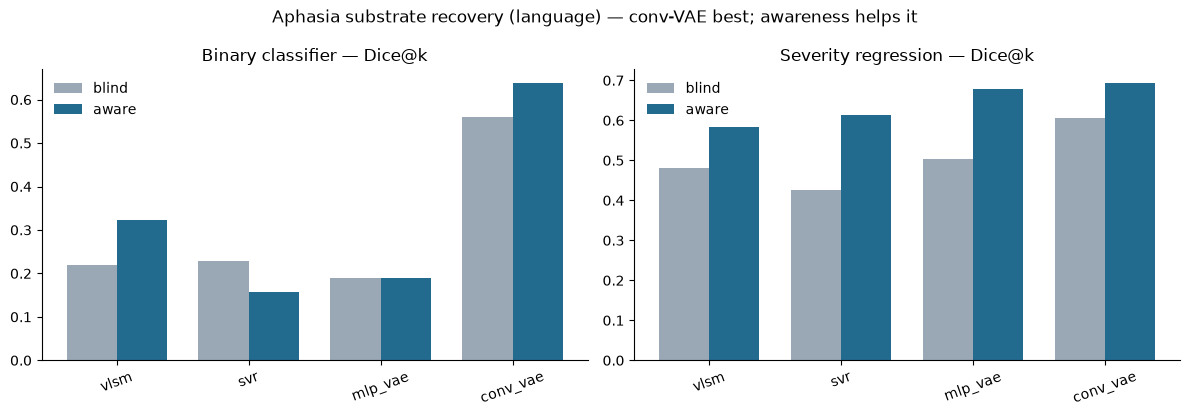

In [5]:
# bar charts: conv-VAE leads and covariate-awareness helps it, on both tasks
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2)); x = np.arange(len(METHODS)); w = 0.38
for ax, res, title in [(axes[0], binary, "Binary classifier"), (axes[1], severity, "Severity regression")]:
    b = [res[me]["blind"]["dice_k"] for me in METHODS]; a = [res[me]["aware"]["dice_k"] for me in METHODS]
    ax.bar(x - w/2, b, w, label="blind", color="#9aa7b5"); ax.bar(x + w/2, a, w, label="aware", color="#236a8f")
    ax.set_xticks(x); ax.set_xticklabels(METHODS, rotation=20); ax.set_title(f"{title} — Dice@k")
    ax.legend(frameon=False); ax.spines[["top","right"]].set_visible(False)
fig.suptitle("Aphasia substrate recovery (language) — conv-VAE best; awareness helps it")
plt.tight_layout(); plt.show()

### Glass brains — conv-VAE recovery vs truth (blue = truth, red = recovered, purple = overlap)

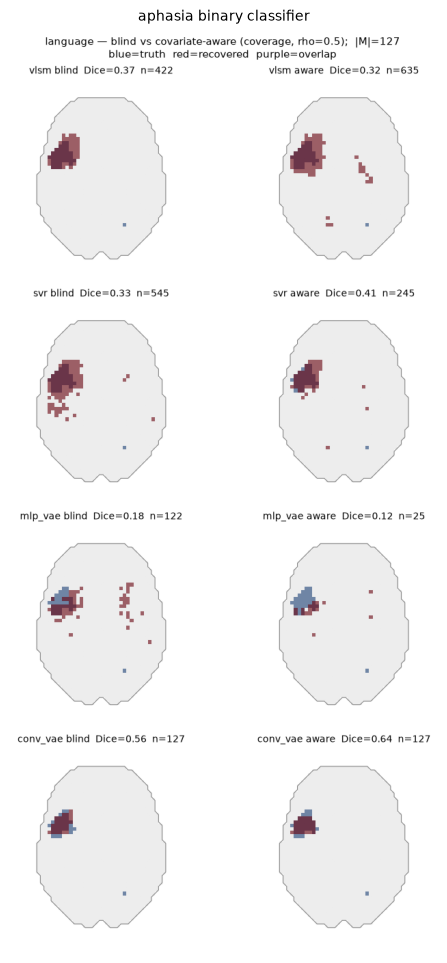

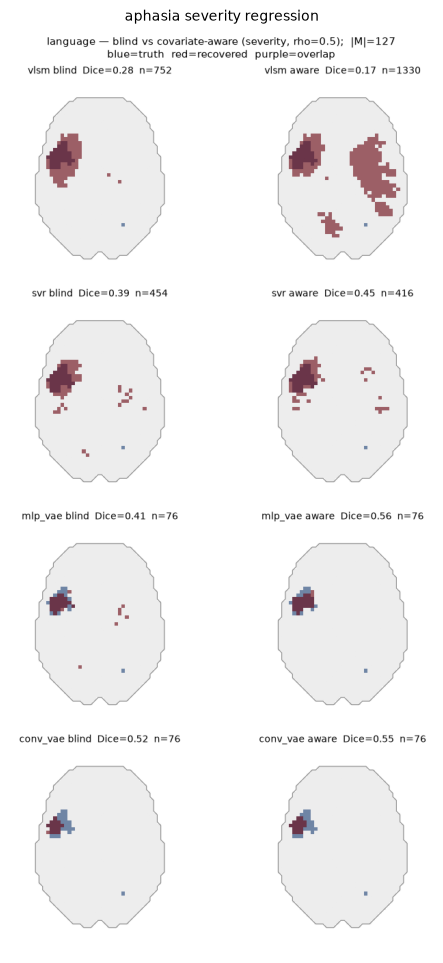

In [6]:
for name, cap in [("james_glassbrain_binary.png", "binary classifier"),
                  ("james_glassbrain_severity.png", "severity regression")]:
    p = f"imgs/{name}"
    try:
        fig, ax = plt.subplots(figsize=(7.5, 12)); ax.imshow(plt.imread(p)); ax.axis("off")
        ax.set_title(f"aphasia {cap}", fontsize=10); plt.show()
    except FileNotFoundError:
        print("(figure not shipped:", p, ")")

## Plug in your own data / run it live

Everything is just `X` (an `N × V` lesion-overlap matrix), `y` (your label), and `cov` (an
`N × d` covariate matrix, e.g. `[age, sex]`). Blind = omit `cov`; aware = pass it.

```python
# binary classifier (aphasia yes/no)
conv = conv_vae.fit_conv_vae(X, y_binary, mask_idx=mask_idx, vol_shape=vol_shape, cov=cov, epochs=300)  # GPU
mlp  = fit_parcel_vae(X, y_binary, cov=cov, epochs=500)                                                  # CPU-ok

# severity regression — set continuous=True (MSE head; y is z-scored internally)
conv = conv_vae.fit_conv_vae(X, severity, mask_idx=mask_idx, vol_shape=vol_shape, cov=cov,
                             continuous=True, epochs=300)
mlp  = fit_parcel_vae(X, severity, cov=cov, continuous=True, epochs=500)
```

A quick **live** run of the fast methods (VLSM + MLP-VAE) on the binary task, blind vs aware —
this is exactly the call pattern; the conv-VAE is the same call with `fit_conv_vae` on a GPU:

In [7]:
y = (make_covariate_benchmark_deficits(data.X, m.astype(np.float32), data.centroids,
        K_parcel=data.n_voxels, beta_main=0.5, beta_int=0.5, rho=0.5, seed=0)[0])["coverage"]
print(f"{'method':10s}{'Dice@k bl':>11s}{'aw':>7s}{'binDice bl':>12s}{'aw':>7s}")
for name, fn in [("vlsm", None), ("mlp_vae", None)]:
    if name == "vlsm":
        sb, mb_ = vlsm_stat(data.X, y, delta=0.10), vlsm_binary(data.X, y, delta=0.10, n_perm=300, seed=0)[0]
        sa, ma = vlsm_stat(data.X, y, delta=0.10, cov=cov), vlsm_binary(data.X, y, delta=0.10, n_perm=300, cov=cov, seed=0)[0]
    else:
        sb = fit_parcel_vae(data.X, y, epochs=200, seed=0); mb_ = focal_mass_mask(sb)
        sa = fit_parcel_vae(data.X, y, cov=cov, epochs=200, seed=0); ma = focal_mass_mask(sa)
    print(f"{name:10s}{dice_at_k(sb,m,k):>11.3f}{dice_at_k(sa,m,k):>7.3f}{dice(mb_,m):>12.3f}{dice(ma,m):>7.3f}")

method      Dice@k bl     aw  binDice bl     aw


vlsm            0.220  0.323       0.368  0.324


mlp_vae         0.244  0.260       0.244  0.260


## Takeaways for these tasks

- **Conv-VAE first.** The 3D spatial prior makes it the strongest substrate recoverer for both a
  binary classifier and a continuous-severity outcome, and it is the method covariate-awareness
  reliably helps (best recovery + lowest confound leakage). The classical methods over-correct when
  age is collinear with lesion volume.
- **Covariates via partialing-out**, entered as `cov=[age, sex]`; the VAEs route them to the deficit
  head only, so the substrate map stays covariate-invariant.
- **Severity = `continuous=True`** on the VAEs (MSE head); VLSM/SVR take the continuous target directly.
- **4 mm now, 2 mm as a refinement.** Same code — rebuild the sample at 2 mm and (if needed) raise the
  coverage threshold; the conv-VAE is the method to carry to higher resolution.